In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats

import seaborn as sns

sns.set(rc={'figure.figsize':(12,6)}, style="whitegrid")

In [2]:
#загружаем данные
groups=pd.read_csv("groups.csv", sep=";")
groups_add=pd.read_csv("group_add.csv")
active_studs=pd.read_csv("active_studs.csv")
checks=pd.read_csv("checks.csv", sep=";")

print("Размеры загруженных таблиц (строки, столбцы)")
print("groups:", groups.shape)
print("groups_add:", groups_add.shape)
print("active_studs:", active_studs.shape)
print("checks:", checks.shape)

Размеры загруженных таблиц (строки, столбцы)
groups: (74484, 2)
groups_add: (92, 2)
active_studs: (8341, 1)
checks: (541, 2)


In [3]:
print("Проверка качества данных")
print("Дубликаты id в groups:", groups["id"].duplicated().sum())
print("Дубликаты id в groups_add:", groups_add["id"].duplicated().sum())
print("Дубликаты в active_studs:", active_studs["student_id"].duplicated().sum())
print("Дубликаты в checks:", checks["student_id"].duplicated().sum())
print("Пропуски (NaN) во всех таблицах:",
      groups.isna().sum().sum() + groups_add.isna().sum().sum()
      + active_studs.isna().sum().sum() + checks.isna().sum().sum())
print("id из groups_add, которые уже есть в groups:",
      groups_add["id"].isin(groups["id"]).sum())

Проверка качества данных
Дубликаты id в groups: 0
Дубликаты id в groups_add: 0
Дубликаты в active_studs: 0
Дубликаты в checks: 0
Пропуски (NaN) во всех таблицах: 0
id из groups_add, которые уже есть в groups: 0


все ок, дублей нигде нет, файлы подготавливать никак не нужно, можно мержить

In [4]:
#объединяю два файла по группам в один
all_groups = pd.concat([groups, groups_add], ignore_index=True)

## Ресерч: связи между таблицами
прежде чем собирать общий датафрейм, проверяю, как таблицы связаны между собой:
- у всех ли активных и платящих пользователей есть группа;
- все ли платящие заходили на платформу. логично ожидать, что чтобы оплатить на сайте, пользователь должен на него зайти, т.е. все из checks должны быть и в active_studs

In [5]:
#проверяю, у всех ли пользователей есть группа
print("активные, у которых нет группы:", (~active_studs["student_id"].isin(all_groups["id"])).sum())
print("платящие, у которых нет группы:", (~checks["student_id"].isin(all_groups["id"])).sum())

#сколько активных пользователей пришло только из дополнительного файла
print("активные из groups_add:", groups_add["id"].isin(active_studs["student_id"]).sum())

активные, у которых нет группы: 0
платящие, у которых нет группы: 0
активные из groups_add: 13


у всех пользователей группа нашлась. 13 активных пользователей есть только в groups_add

In [6]:
#поиск пользователей, которые заплатили, но НЕ заходили на платформу во время эксперимента
paid_not_active = checks[~checks["student_id"].isin(active_studs["student_id"])]
print("платящие без активности:", len(paid_not_active),
      f"из {len(checks)} ({len(paid_not_active) / len(checks):.0%})")

#проверяю, в каких они группах и сколько заплатили
paid_not_active = paid_not_active.merge(all_groups, left_on="student_id", right_on="id")
print(paid_not_active.groupby("grp")["rev"].agg(["count", "mean", "sum"]).round(1))

платящие без активности: 149 из 541 (28%)
     count   mean      sum
grp                       
A       29  664.7  19276.0
B      120  718.8  86256.0


найдено 149 пользователей (28% всех оплат), которые заплатили, но на платформу в дни эксперимента не заходили. они есть в обеих группах

возможные причины:
- автоматические списания (автопродление подписки);
- оплата через другой канал (приложение, ссылка из письма, менеджер);
- ошибка в логировании активности

**решение: исключаем их из анализа.** эти пользователи не видели страницу оплаты, значит новая механика на них повлиять не могла, поэтому дальше берём только активных пользователей (inner join с active_studs).
о проблеме стоит сообщить команде, которая отвечает за сбор данных

In [7]:
#делаю общий датафрейм: добавляю оплаты и оставляю только тех пользователей, 
# которые заходили во время эксеперимента (active_studs)
df = (
    active_studs
    .merge(all_groups, left_on="student_id", right_on="id", how="inner")
    .drop(columns="id")                               
    .merge(checks, on="student_id", how="left")
)

In [8]:
#заменим NaN на 0 и сдлеаем вторую колонку платящий ли пользователь
df["rev"] = df["rev"].fillna(0)    
df["is_payer"] = df["rev"] > 0    

print("Всего пользователей:", len(df))
print("Всего платящих:", df["is_payer"].sum())

Всего пользователей: 8341
Всего платящих: 392


In [9]:
print("Итоговое разбиение на группы")
print("Всего пользователей в эксперименте:", len(df))
print(df["grp"].value_counts())
print("Доли групп:")
print(df["grp"].value_counts(normalize=True).round(4))

Итоговое разбиение на группы
Всего пользователей в эксперименте: 8341
grp
B    6803
A    1538
Name: count, dtype: int64
Доли групп:
grp
B    0.8156
A    0.1844
Name: proportion, dtype: float64


итого: группы оказались не равными (примерно 80на20), будем сравнивать относительные показатели

### SRM-проверка
группы неравные, это нормально, если так задумано. но надо проверить, что среди активных пропорция групп такая же, как в исходном разбиении, если различается, то есть вероятность, что сплит или логирование могли работать некорректно

тест: хи-квадрат на соответствие ожидаемым долям (chisquare), т.к. сравниваем наблюдаемые количества с ожидаемыми

- **H0:** доли групп среди активных совпадают с долями в исходном разбиении
- **H1:** доли групп среди активных отличаются от исходного разбиения

уровень значимости α = 0.05

In [10]:
#ожидаемые доли беру из исходного разбиения (все пользователи), фактические — среди активных
expected_share = all_groups["grp"].value_counts(normalize=True)[["A", "B"]]
observed = df["grp"].value_counts()[["A", "B"]]
expected = expected_share * observed.sum()

stat, p_srm = stats.chisquare(f_obs=observed, f_exp=expected)
print("ожидаемая доля A:", round(expected_share["A"], 4),
      "| фактическая среди активных:", round(observed["A"] / observed.sum(), 4))
print(f"p-value = {p_srm:.4f}")

ожидаемая доля A: 0.197 | фактическая среди активных: 0.1844
p-value = 0.0037


p ≈ 0.004 < 0.05 → H0 отклоняем: доля группы A среди активных (18.4%) статистически значимо ниже, чем в исходном разбиении (19.7%). разница небольшая (~120 человек), но это сигнал, что сплит или логирование могли работать неидеально. анализ продолжаем, но учитываем это в выводах

выбираю метрики для проверки гипотезы с механикой оплаты
она может изменить:
- долю людей, которые решаются заплатить;
- сумму, которую платит человек.
буду рассматривать следующие метрики:
1.CR - конверсия активного пользователя в оплату: CR = число платящих / число активных
2.ARPPU — средний чек платящего: ARPPU = выручка / число платящих
3. ARPU — выручка на активного: ARPU = выручка / число активных = CR * ARPPU
эта метрика объединяет две предыдущие, чтобы понять в итоге выигрываем с новой механикой или нет

In [11]:
#посмотрим на абсолютные изменения метрик (пока без тестов стат.значимости)
metrics = df.groupby("grp").agg(
    active_users=("student_id", "count"),
    payers=("is_payer", "sum"),
    revenue=("rev", "sum"),
)
metrics["CR, %"] = metrics["payers"] / metrics["active_users"] * 100
metrics["ARPPU"] = metrics["revenue"] / metrics["payers"]
metrics["ARPU"] = metrics["revenue"] / metrics["active_users"]

print("Метрики по группам")
print(metrics.round(2))

#относительное изменение B к A в %
uplift = (metrics.loc["B", ["CR, %", "ARPPU", "ARPU"]]
          / metrics.loc["A", ["CR, %", "ARPPU", "ARPU"]] - 1) * 100
print("\nИзменение B относительно A, %:")
print(uplift.round(1))

Метрики по группам
     active_users  payers   revenue  CR, %    ARPPU   ARPU
grp                                                       
A            1538      78   72820.0   5.07   933.59  47.35
B            6803     314  394974.0   4.62  1257.88  58.06

Изменение B относительно A, %:
CR, %    -9.0
ARPPU    34.7
ARPU     22.6
dtype: float64


CR в B чуть ниже (-9%)
ARPPU в B заметно выше (+35%)
ARPU в B выше (+23%)

## Проверка условий для выбора стат.тестов
для денежных метрик (ARPPU, ARPU) мы сравниваем средние. классический t-тест Стьюдента требует двух условий:
1. распределения в группах **нормальные**;
2. **дисперсии** в группах равны.

проверяем оба условия для обеих метрик:
- ARPPU — чеки только платящих пользователей;
- ARPU — выручка всех активных пользователей (включая нули у неплатящих)

In [12]:
#проверяем группы платящих пользователей на нормальность, чтобы выбрать тест
payers = df[df["is_payer"]]
rev_a = payers.query('grp == "A"')["rev"].values
rev_b = payers.query('grp == "B"')["rev"].values

### Нормальность чеков платящих (ARPPU)
тест Шапиро-Уилка — подходит для выборок до ~5000 наблюдений (у нас 78 и 314)
- **H0:** распределение чеков нормальное
- **H1:** распределение чеков не нормальное

In [13]:
#тест Шапиро-Уилка на нормальность: H0 — распределение нормальное
stat_a, p_a = stats.shapiro(rev_a)
stat_b, p_b = stats.shapiro(rev_b)

print(f"Группа A: W = {stat_a:.4f}, p = {p_a:.2e}")
print(f"Группа B: W = {stat_b:.4f}, p = {p_b:.2e}")

Группа A: W = 0.7353, p = 1.50e-10
Группа B: W = 0.8547, p = 1.54e-16


p-value ниже 0.05, следовательно Н0 отклоняется, распределение чеков НЕ нормальное в обеих группах

<Axes: xlabel='rev', ylabel='Count'>

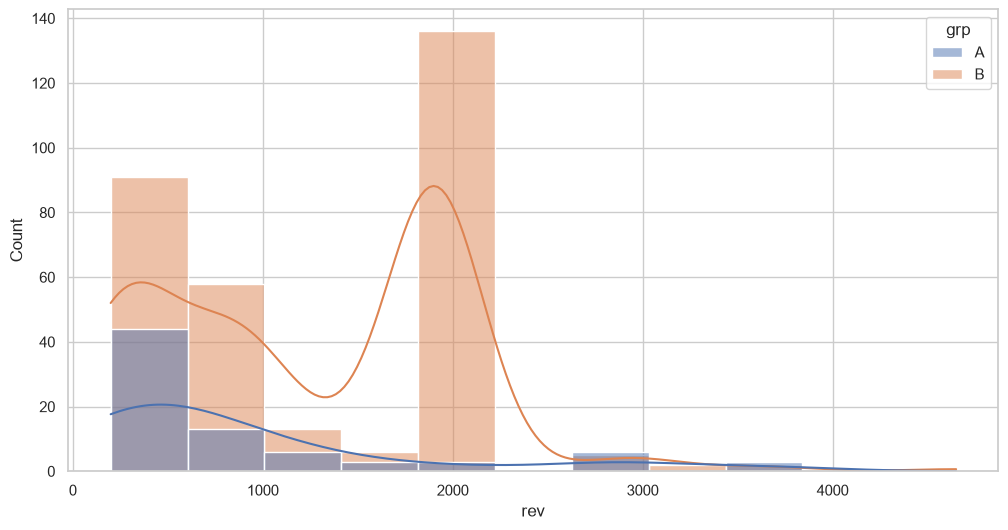

In [14]:
#построим гистограмму, чтобы визуально увидеть не нормальность распределений
sns.histplot(data=payers, x="rev", hue="grp", kde=True)

на графике видно несколько пиков вместо одного, у группы B выделяется большой пик в районе 1900. посмотрим самые частые суммы чека

In [15]:
#самые частые суммы чека в каждой группе
for g in ["A", "B"]:
    print(g, payers.query('grp == @g')["rev"].round().value_counts().head(5).to_dict())

A {290.0: 25, 580.0: 6, 590.0: 5, 199.0: 5, 990.0: 5}
B {1900.0: 128, 290.0: 45, 199.0: 27, 840.0: 21, 990.0: 17}


в группе B 128 оплат ровно на 1900 руб. (самый частый чек, ~40% платящих), а в группе A таких нет совсем. часть из них записана как 1900.0001 — похоже на особенность расчёта цены в новой механике. вероятно, новая механика продвигает конкретный тариф за 1900 — именно он может "тянуть" средний чек B вверх. это нужно уточнить у продукта

### Нормальность выручки на активного (ARPU)
Шапиро-Уилк ненадёжен на выборках больше 5000 (в группе B 6803 пользователя), поэтому используем тест Д'Агостино-Пирсона (stats.normaltest) — он рассчитан на большие выборки
- **H0:** распределение выручки нормальное
- **H1:** распределение выручки не нормальное

In [16]:
#выручка всех активных пользователей (у неплатящих 0)
rev_all_a = df.query('grp == "A"')["rev"].values
rev_all_b = df.query('grp == "B"')["rev"].values

#тест Д'Агостино-Пирсона на нормальность
stat_a, p_a = stats.normaltest(rev_all_a)
stat_b, p_b = stats.normaltest(rev_all_b)
print(f"Группа A: p = {p_a:.2e}")
print(f"Группа B: p = {p_b:.2e}")

#доля нулей (неплатящих) в каждой группе
print("доля нулей: A =", round((rev_all_a == 0).mean(), 3), "| B =", round((rev_all_b == 0).mean(), 3))

Группа A: p = 0.00e+00
Группа B: p = 0.00e+00
доля нулей: A = 0.949 | B = 0.954


p-value ≈ 0 → H0 отклоняется, распределение НЕ нормальное. это ожидаемо: ~95% значений — нули (неплатящие), и только ~5% — положительные чеки

### Равенство дисперсий
тест Левена (stats.levene) с center="median" — этот вариант устойчив к ненормальным данным 
- **H0:** дисперсии в группах равны
- **H1:** дисперсии в группах различаются

In [17]:
#тест Левена на равенство дисперсий
_, p_lev_arppu = stats.levene(rev_a, rev_b, center="median")
_, p_lev_arpu = stats.levene(rev_all_a, rev_all_b, center="median")

print(f"ARPPU: std A = {rev_a.std():.1f}, std B = {rev_b.std():.1f}, p = {p_lev_arppu:.4f}")
print(f"ARPU: std A = {rev_all_a.std():.1f}, std B = {rev_all_b.std():.1f}, p = {p_lev_arpu:.4f}")

ARPPU: std A = 914.0, std B = 789.6, p = 0.0803
ARPU: std A = 290.4, std B = 313.7, p = 0.2205


p > 0.05 для обеих метрик → H0 не отклоняется, статистически значимых различий в дисперсиях нет

**итог проверки условий:**

| Метрика | Нормальность | Равенство дисперсий |
|---------|--------------|---------------------|
| ARPPU   | НЕТ          | ДА (p ≈ 0.08)       |
| ARPU   | НЕТ          | ДА (p ≈ 0.22)       |

условие нормальности не выполняется → классический t-тест Стьюдента в чистом виде применять некорректно

## Обоснование выбора стат.тестов

**CR (конверсия) → хи-квадрат (chi2_contingency)**
- на уровне пользователя метрика бинарная: заплатил / не заплатил;
- сравниваем доли в двух независимых группах → таблица сопряжённости 2×2;
- условие применимости: ожидаемые частоты в каждой ячейке ≥ 5 (проверяем ниже)

**ARPPU и ARPU (средние денежные метрики) → bootstrap + t-тест Уэлча для подтверждения**

- **bootstrap** — выбран основным: не требует нормальности, сравнивает именно средние и даёт доверительный интервал разницы в рублях, который легко интерпретировать;
- **t-тест Уэлча** — используем для подтверждения: сравнивает средние и не требует равенства дисперсий. при ненормальных данных работает за счёт центральной предельной теоремы (выборки достаточно большие: 78/314 платящих, 1538/6803 активных). выбрали Уэлча, а не Стьюдента, т.к. группы сильно неравны по размеру (≈ 1:4), а на неравных группах тест Стьюдента чувствителен даже к небольшим различиям дисперсий

уровень значимости для всех тестов α = 0.05

In [18]:
#ТЕСТ для конверсии: хи-квадрат
# H0: конверсия в группах одинаковая
# H1: конверсия различается

contingency = pd.crosstab(df["grp"], df["is_payer"])
chi2, p, dof, expected = stats.chi2_contingency(contingency)
print (p)

0.48625240457231045


ожидаемые частоты везде > 5, хи-квадрат применим

p≈0.49 < 0.05, значит Н0 не отклоняется, следовательно, различие конверсии в группах статистически НЕ значимо
с новой механикой пользователи не стали платить чаще

### Bootstrap
10 000 раз случайно выбираем пользователей с возвращением, считаем разницу средних B - A и берём 2.5-й и 97.5-й процентили — это 95% доверительный интервал разницы
- **H0:** разница средних = 0 (метрика в группах одинаковая)
- **H1:** разница средних ≠ 0 (метрика в группах различается)

если 0 НЕ попадает в 95% ДИ → H0 отклоняем

In [19]:
#ТЕСТ для денежных метрик
#распределение НЕ нормальное и данных платящих пользователей не так много на обе группы (392)
#будем применять bootstrap

#сначала сама функция для bootstrap оценки средних и 95% доверительного интервала

def bootstrap_mean_diff(a, b, n_iter=10_000):
    diffs = np.empty(n_iter)
    for i in range(n_iter):
        sample_a = np.random.choice(a, size=len(a), replace=True)
        sample_b = np.random.choice(b, size=len(b), replace=True)
        diffs[i] = sample_b.mean() - sample_a.mean()
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    return b.mean() - a.mean(), ci_low, ci_high, diffs

In [20]:
#ARPPU: сравниваем чеки платящих
diff, lo, hi, boot_arppu = bootstrap_mean_diff(rev_a, rev_b)
print("ARPPU (средний чек платящего):")
print(f"  разница B - A = {diff:.1f} руб., 95% ДИ bootstrap: [{lo:.1f}; {hi:.1f}]")
print("  ->", "различие ЗНАЧИМО" if lo > 0 or hi < 0 else "различие НЕ значимо")

ARPPU (средний чек платящего):
  разница B - A = 324.3 руб., 95% ДИ bootstrap: [92.3; 537.0]
  -> различие ЗНАЧИМО


In [21]:
#подтверждаем результат по ARPPU t-тестом Уэлча (equal_var=False)
# H0: средний чек платящего в группах одинаковый
# H1: средний чек платящего в группах различается
print(f"t-тест Уэлча ARPPU: p = {stats.ttest_ind(rev_b, rev_a, equal_var=False).pvalue:.4f}")

t-тест Уэлча ARPPU: p = 0.0051


0 не входит в 95% ДИ, Уэлч p ≈ 0.005 < 0.05 → H0 отклоняем: средний чек платящего в группе B статистически значимо выше

In [22]:
#ARPU: сравниваем выручку на всех активных пользователей (платящих/не платящх)
rev_all_a = df.query('grp == "A"')["rev"].values
rev_all_b = df.query('grp == "B"')["rev"].values
diff, lo, hi, boot_arpu = bootstrap_mean_diff(rev_all_a, rev_all_b)
print(f"  разница B - A = {diff:.1f} руб., 95% ДИ bootstrap: [{lo:.1f}; {hi:.1f}]")
print("  ->", "различие ЗНАЧИМО" if lo > 0 or hi < 0 else "различие НЕ значимо")

  разница B - A = 10.7 руб., 95% ДИ bootstrap: [-6.8; 26.5]
  -> различие НЕ значимо


In [23]:
#подтверждаем результат по ARPU t-тестом Уэлча
# H0: выручка на активного пользователя в группах одинаковая
# H1: выручка на активного пользователя в группах различается
print(f"t-тест Уэлча ARPU: p = {stats.ttest_ind(rev_all_b, rev_all_a, equal_var=False).pvalue:.4f}")

t-тест Уэлча ARPU: p = 0.1984


0 входит в 95% ДИ, Уэлч p ≈ 0.20 > 0.05 → H0 не отклоняется: различие выручки на активного пользователя статистически НЕ значимо

## Результаты

Метрики, которые изучали
- Конверсия CR
- Средний чек платящего пользователя ARPPU
- Выручка на активного пользователя ARPU

| Метрика | Значимость                       |
|---------|----------------------------------|
| CR      | НЕТ (хи-квадрат, p ≈ 0.49)       |
| ARPPU   | ДА  (bootstrap ДИ не включает 0) |
| ARPU   | НЕТ (bootstrap ДИ включает 0)    |

Отсутствие роста конверсии: новая механика не сделала оплату "проще" настолько, чтобы платить начали чаще.
Однако средний чек на платящего пользователя увеличился. Платящие пользователи в группе B платят в среднем больше, чем в A.

Итог: новая механика влияет на сумму оплаты (платящие платят больше), но не на решение платить. 
Эффекта на выручку в расчёте на всех активных пользователей тест не показал. 

Конверсия в группе B немного ниже, чем в контрольной, однако стат.не значимо (хи-квадрат). Но в дальнейшем при запуске механики надо на эту метрику обращать внимание

#### Итого: механику запускаем с последующим отслеживанием метрик
#### Дополнительно (ресерч и проверка условий)
- нашли 149 пользователей (28% оплат), которые заплатили, но не заходили на платформу — исключили их, т.к. новую механику они не видели;
- SRM-проверка: доля группы A среди активных значимо ниже ожидаемой (p ≈ 0.004) — возможна проблема в сплитовании или логировании;
- распределения ARPPU и ARPU не нормальные, дисперсии статистически не различаются → для денежных метрик выбрали bootstrap (основной) и t-тест Уэлча (подтверждение), для конверсии — хи-квадрат;
- в группе B 128 оплат ровно на 1900 руб., которых нет в группе A — перед запуском стоит уточнить у продукта их природу, а также проверить сплит и логирование